# Project: Expense Data Visualization Dashboard

<div>
	<img src="../../matplotlib/Images/Mat_project.png" style="border-radius: 30px; max-width: 80%;">
</div>

# Project roadmap

Step 1 — Load and inspect the data\
Load your cleaned expense CSV and check its columns, data types, and missing values.

Step 2 — Category analysis\
Create bar charts showing which categories account for the most spending.

Step 3 — Daily spending trends\
Use line plots to visualize how expenses change day-wise over time.

Step 4 — Transaction number vs expense amount\
Use scatter plots to visualize how expenses are scatter according to there transaction number.

Step 5 — Distribution and comparisons\
Create histograms and subplots to compare spending patterns.

Step 6 — Create a dashboard\
Create four subplots and fill them with the four plots you created earlier.

# Project Starting

## Step 1 — Load and inspect your data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Numpy version :", np.__version__)

Libraries imported successfully!
Pandas version: 3.0.5
Numpy version : 2.5.2


Next, let's verify the location of your cleaned expense data before loading it.

In [9]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nCSV files in the current directory:")
for file in Path.cwd().glob("*.csv"):
    print(file.name)

Current working directory:
C:\Users\rohan\OneDrive\Desktop\Python\Practice\Projects\matplotlib-project

CSV files in the current directory:


The CSV listing is empty, which means there are currently no CSV files directly inside this folder. That's fine—we can load your existing expense dataset from its original location.

**Locate your expense dataset**\
You previously organized your raw and cleaned expense files under pandas/data/. Let's check whether that structure still exists.

In [10]:
from pathlib import Path

base_path = Path.cwd().parent.parent

print("Checking for expense CSV files...\n")

for file in base_path.rglob("*.csv"):
    if "expense" in file.name.lower():
        print(file)

Checking for expense CSV files...

C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\Boss_expense.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\expenses.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\expenses_cleaned.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\Projects\.ipynb_checkpoints\final_expense_analysis-checkpoint.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\Projects\expense-analysis-pandas\final_expense_analysis.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\Projects\matplotlib-project\data\final_expense_analysis.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\Projects\expense-analysis-pandas\.ipynb_checkpoints\final_expense_analysis-checkpoint.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\.ipynb_checkpoints\Boss_expense-checkpoint.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\.ipynb_checkpoints\expenses-checkpoint.csv
C:\Users\rohan\OneDrive\Desktop\Python\Practice\pandas\.ipynb_checkpoints\expense

This searches the parent project directories for CSV filenames containing expense.

For this project, let's use your processed, cleaned dataset so we can focus on visualization rather than repeating data cleaning.
File selected:

pandas/data/processed/expenses_cleaned.csv

**Load the cleaned dataset**

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = (
    Path.cwd().parent.parent
    / "pandas"
    / "data"
    / "processed"
    / "expenses_cleaned.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (6, 3)

Column names:
['date', 'category', 'amount']

First 5 rows:


,date,category,amount
0,2026-01-01,Food,250
1,2026-01-02,Transport,120
2,2026-01-03,Food,300
3,2026-01-05,Shopping,800
4,2026-01-06,Bills,1000



Data types:
date          str
category      str
amount      int64
dtype: object

Missing values:
date        0
category    0
amount      0
dtype: int64


What we're checking
- df.shape — number of rows and columns.
- df.columns — the available fields for visualization.
- df.head() — a preview of your expense records.
- df.dtypes — whether dates and amounts have appropriate data types.
- df.isnull().sum() — missing values in each column.

**Prepare the data**
Before plotting, convert date from a string to a proper datetime type. This will help us analyze expenses over time.

In [12]:
# Convert date strings to datetime
df["date"] = pd.to_datetime(df["date"])

# Verify data types
print(df.dtypes)

# Display the dataset
display(df)

date        datetime64[us]
category               str
amount               int64
dtype: object


,date,category,amount
0,2026-01-01,Food,250
1,2026-01-02,Transport,120
2,2026-01-03,Food,300
3,2026-01-05,Shopping,800
4,2026-01-06,Bills,1000
5,2026-01-08,Transport,150


## Step 2 — Category analysis
Let's calculate the total expenses in each category and display them in a bar chart.

First, calculate the totals:

In [13]:
category_totals = (
    df.groupby("category")["amount"]
        .sum()
        .sort_values(ascending=False)
)

print(category_totals)

category
Bills        1000
Shopping      800
Food          550
Transport     270
Name: amount, dtype: int64


Then visualize them:

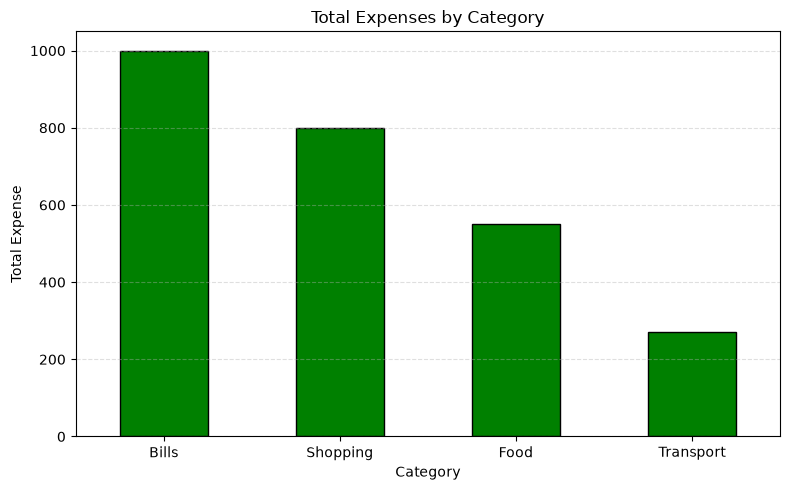

In [14]:
plt.figure(figsize=(8, 5))

category_totals.plot(
    kind="bar",
    color="green",
    edgecolor="black"
)

plt.title("Total Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Total Expense")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.show()

What you should learn from this chart
- Which category has the highest total expense?
- Which category has the lowest total expense?
- How does groupby() prepare data for visualization?
- Why is sorting the totals useful?

## Step 3 — Daily spending trends
Now let's create a line chart showing how your expenses change by date.

Since the dataset has multiple expenses on some dates potentially, we'll group by date first to calculate total spending per day.

In [15]:
# Calculate total expenses per day
daily_expenses = (
    df.groupby("date")["amount"]
        .sum()
        .sort_index()
)

print(daily_expenses)

date
2026-01-01     250
2026-01-02     120
2026-01-03     300
2026-01-05     800
2026-01-06    1000
2026-01-08     150
Name: amount, dtype: int64


Now plot the results:

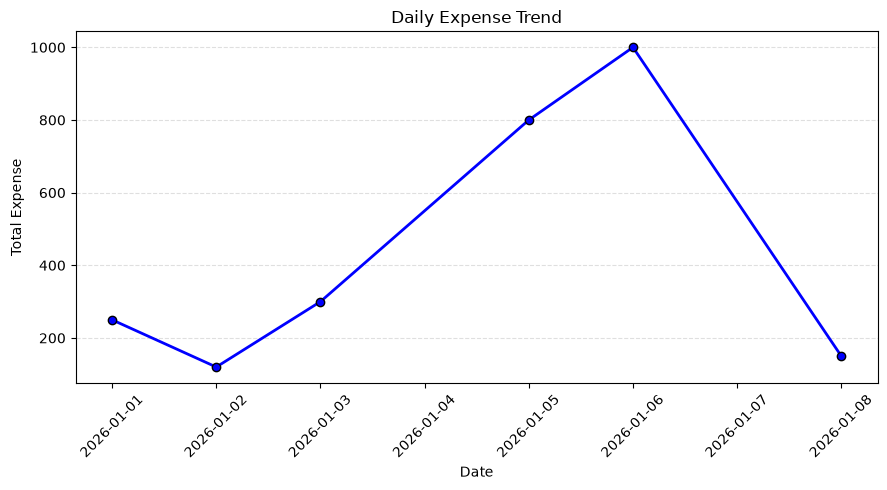

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    daily_expenses.index,
    daily_expenses.values,
    marker="o",
    color="blue",
    markeredgecolor="black",
    linestyle="-",
    lw=2
)

plt.title("Daily Expense Trend")
plt.xlabel("Date")
plt.ylabel("Total Expense")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.show()

What to observe
- Each point represents the total expense on a date.
- The line shows how spending changes over time.
- The highest point represents the date with the greatest daily spending.

## Step 4 — Transaction number vs expense amount
Now let's create a scatter plot showing expenses with there transaction number.

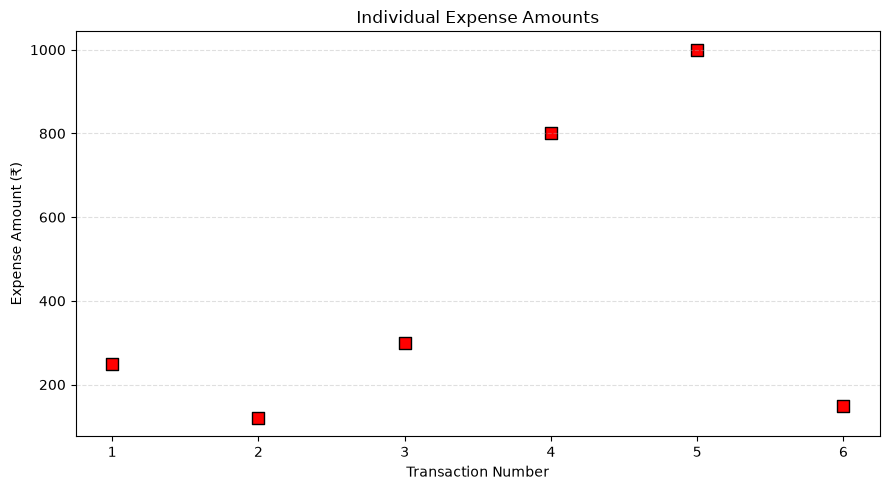

In [17]:
plt.figure(figsize=(9, 5))

transaction_number = np.arange(1, len(df) + 1)

plt.scatter(
    transaction_number,
    df["amount"],
    marker="s",
    color="red",
    edgecolor="black",
    s=80
)

plt.title("Individual Expense Amounts")
plt.xlabel("Transaction Number")
plt.ylabel("Expense Amount (₹)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.show()

## Step 5 — Distribution and comparisons
A histogram helps us understand how your individual expenses are distributed: whether most expenses are small, large, or concentrated in a particular range.

### 1. Create the histogram
Use the amount column from your existing df DataFrame.

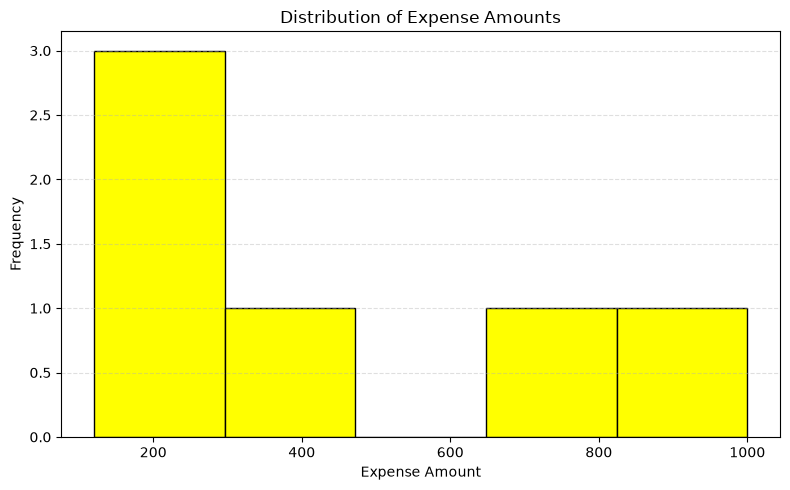

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["amount"],
    bins=5,
    color="yellow",
    edgecolor="black"
)

plt.title("Distribution of Expense Amounts")
plt.xlabel("Expense Amount")
plt.ylabel("Frequency")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 2. Understand the output
- X-axis: Ranges of expense amounts.
- Y-axis: Number of expenses that fall within each range.
- bins=5: Divides the range of expense values into five intervals.
- edgecolor="black": Adds borders to the bars so the intervals are easier to distinguish.

Remember: unlike a bar chart, a histogram groups numerical values into ranges. The bars usually touch because the ranges are continuous.

### 3. Interpret your data
After running the code, look at the histogram and ask yourself:
1. Which expense range contains the most records?
2. Are most of your expenses relatively small or large?
3. Does the histogram reveal any unusually high expenses?

## Step 6 — Create the dashboard
Add a new cell to your expense_visualization.ipynb notebook and try filling in the four subplots yourself.

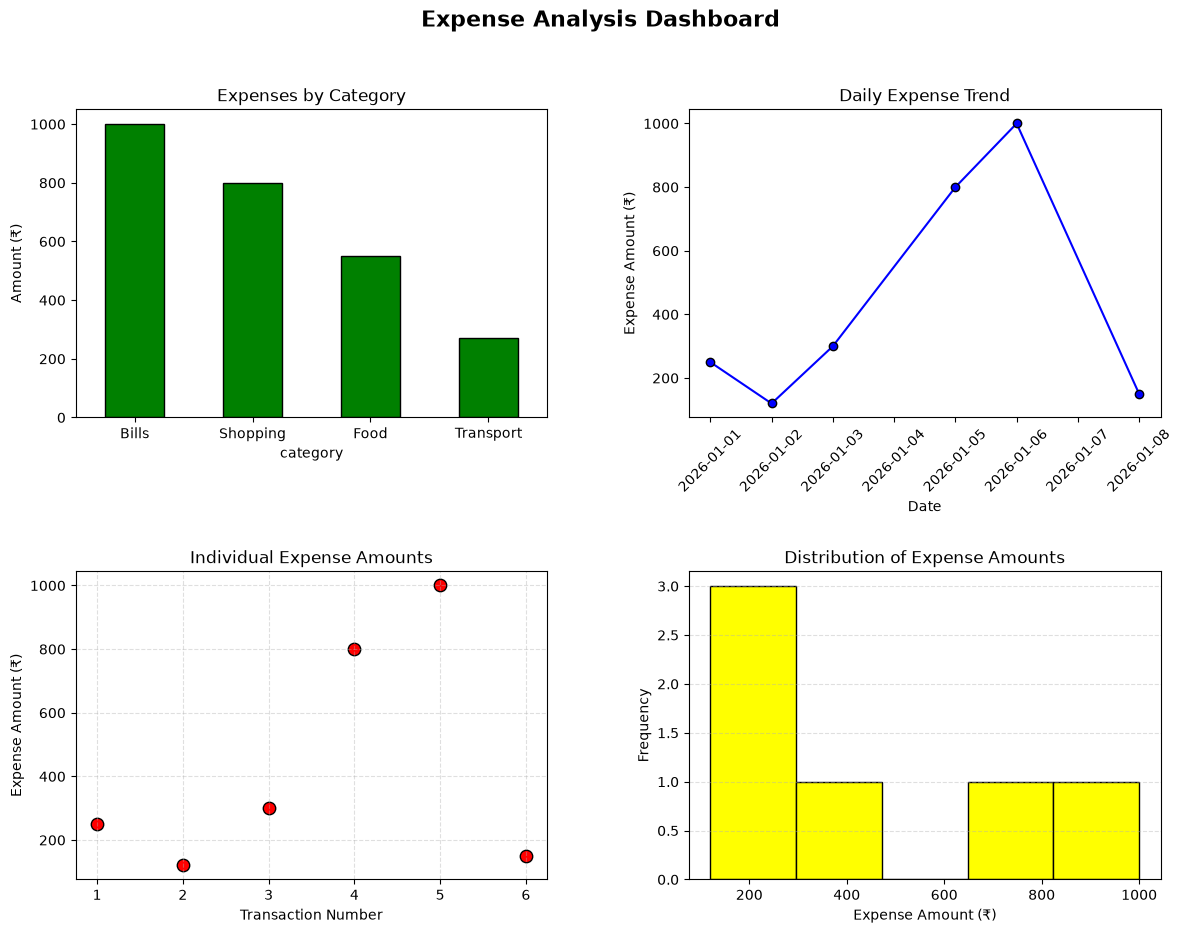

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Category-wise expenses
category_totals.plot(
    kind="bar",
    color="green",
    edgecolor="black",
    ax=ax[0, 0]
)

ax[0, 0].set_title("Expenses by Category")
ax[0, 0].set_ylabel("Amount (₹)")
ax[0, 0].tick_params(axis="x", rotation=0)

# 2. Daily expense trend
ax[0, 1].plot(
    daily_expenses.index,
    daily_expenses.values,
    marker="o",
    color="blue",
    markeredgecolor="black"
)

ax[0, 1].set_title("Daily Expense Trend")
ax[0, 1].tick_params(axis="x", rotation=45)
ax[0, 1].set_xlabel("Date")
ax[0, 1].set_ylabel("Expense Amount (₹)")

# 3. Transaction number vs expense amount
transaction_number = np.arange(1, len(df) + 1)

ax[1, 0].scatter(
    transaction_number,
    df["amount"],
    color="red",
    edgecolor="black",
    s=80
)

ax[1, 0].set_title("Individual Expense Amounts")
ax[1, 0].set_xlabel("Transaction Number")
ax[1, 0].set_ylabel("Expense Amount (₹)")
ax[1, 0].grid(True, linestyle="--", alpha=0.4)

# 4. Distribution of expense amounts
ax[1, 1].hist(
    df["amount"],
    bins=5,
    color="yellow",
    edgecolor="black"
)

ax[1, 1].set_title("Distribution of Expense Amounts")
ax[1, 1].set_xlabel("Expense Amount (₹)")
ax[1, 1].set_ylabel("Frequency")
ax[1, 1].grid(axis="y", linestyle="--", alpha=0.4)

fig.subplots_adjust(
    hspace=0.5,  # Vertical gap between rows
    wspace=0.3   # Horizontal gap between columns
)

fig.suptitle(
    "Expense Analysis Dashboard",
    fontsize=16,
    fontweight="bold"
)

plt.show()

# End of Project